In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pickle
from wordcloud import WordCloud
import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv(r"C:\Users\jubai\spam-detector\data\spam.csv", encoding='latin-1')[['v1', 'v2']]
df.columns = ['label', 'message']
df['label'] = df['label'].map({'ham': 0, 'spam': 1})


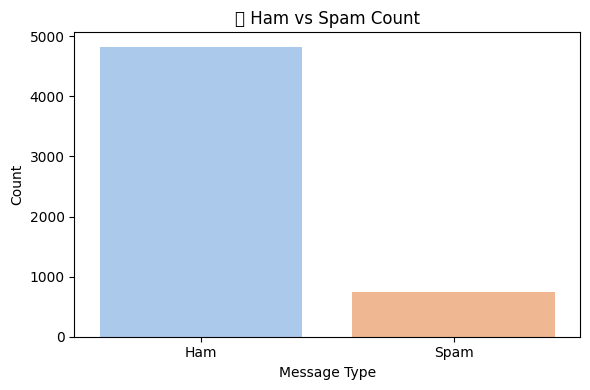

In [3]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', palette='pastel')
plt.title('📊 Ham vs Spam Count')
plt.xticks(ticks=[0, 1], labels=['Ham', 'Spam'])
plt.xlabel('Message Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


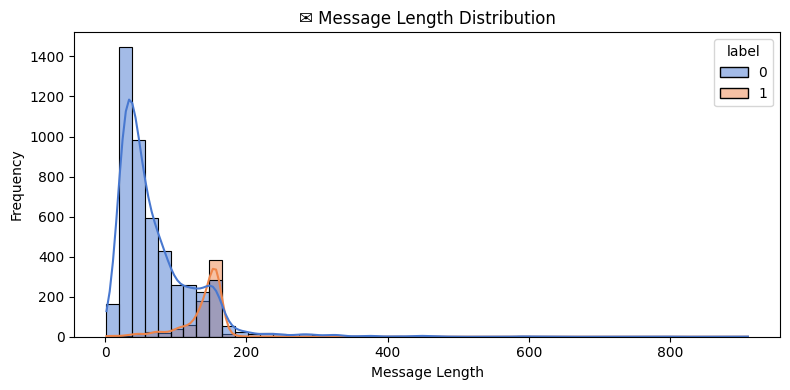

In [4]:
df['length'] = df['message'].apply(len)

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='length', hue='label', bins=50, kde=True, palette='muted')
plt.title('✉️ Message Length Distribution')
plt.xlabel('Message Length')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


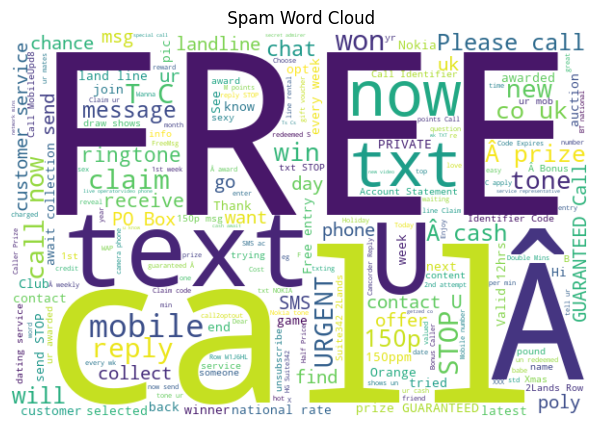

In [5]:
spam_words = ' '.join(df[df['label'] == 1]['message'])
spam_wc = WordCloud(width=600, height=400, background_color='white').generate(spam_words)

plt.figure(figsize=(8, 5))
plt.imshow(spam_wc, interpolation='bilinear')
plt.axis('off')
plt.title(' Spam Word Cloud')
plt.show()


In [6]:
X_train, X_test, y_train, y_test = train_test_split(df['message'], df['label'], test_size=0.2, random_state=42)


In [7]:
model = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', MultinomialNB())
])

model.fit(X_train, y_train)


Pipeline(steps=[('tfidf', TfidfVectorizer()), ('clf', MultinomialNB())])

In [ ]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\n Accuracy of the model: {accuracy:.4f}\n")
print(" Classification Report:")
print(classification_report(y_test, y_pred))


In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


In [ ]:
with open('spam_model.pkl', 'wb') as f:
    pickle.dump(model, f)

print("\n Model saved as spam_model.pkl ")
print(" All tasks completed successfully! Your spam detector is ready to go.")
